In [1]:
import pandas as pd
from IPython.display import Image, display

import analysis
from energy_calculator import RoomManager

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

manager = RoomManager()
skipped = manager.load_csv("data/rooms.csv")

table = pd.DataFrame(manager.energy_table(),
                     columns=["room_id", "room_name", "building", "kwh_per_day", "kwh_per_m2_day"]).round(3)
display(table)
print(f"Total estimated consumption: {manager.total_daily_energy():.2f} kWh/day")
print("Per building:", {b: round(v, 2) for b, v in manager.energy_by_building().items()})

Total estimated consumption: 1050.70 kWh/day
Per building: {'Admin Block': 518.2, 'Academic Block': 532.5}


,room_id,room_name,building,kwh_per_day,kwh_per_m2_day
0,R01,Open Office,Admin Block,143.0,1.192
1,R02,Meeting Room,Admin Block,28.8,0.823
2,R03,Manager Office,Admin Block,29.6,1.057
3,R04,Server Room,Admin Block,316.8,15.840
4,R05,Lecture Hall,Academic Block,131.2,0.875
5,R06,Computer Lab,Academic Block,132.3,1.654
6,R07,Library,Academic Block,185.0,0.925
7,R08,Cafeteria,Academic Block,84.0,0.933


In [2]:
rooms = analysis.load_rooms("data/rooms.csv")
raw = analysis.load_readings("data/readings.csv")
clean, report = analysis.clean_readings(raw, set(rooms["room_id"]))

for key, value in report.items():
    print(f"{key.replace('_', ' '):<30} {value}")

rows in                        490
invalid dates dropped          0
unknown rooms dropped          0
duplicates removed             2
negative values set missing    0
missing values found           3
missing values left            0
rows out                       488


In [3]:
price = 2.0  # example price per kWh
merged = analysis.add_cost(analysis.merge_data(clean, rooms), price)
merged.head()

,room_id,date,actual_kwh,day_type,room_name,building,area_m2,lighting_kw,ac_kw,equipment_kw,hours_per_day,estimated_daily_kwh,month,cost
0,R01,2026-08-01,59.10,weekend,Open Office,Admin Block,120,1.8,9.0,3.5,10,143.0,2026-08,118.20
1,R01,2026-08-02,61.95,weekend,Open Office,Admin Block,120,1.8,9.0,3.5,10,143.0,2026-08,123.90
2,R01,2026-08-03,112.76,weekday,Open Office,Admin Block,120,1.8,9.0,3.5,10,143.0,2026-08,225.52
3,R01,2026-08-04,117.46,weekday,Open Office,Admin Block,120,1.8,9.0,3.5,10,143.0,2026-08,234.92
4,R01,2026-08-05,107.23,weekday,Open Office,Admin Block,120,1.8,9.0,3.5,10,143.0,2026-08,214.46


In [4]:
comparison = analysis.room_comparison(merged, rooms)
comparison[["room_id", "room_name", "building", "total_kwh", "total_cost",
            "estimated_total_kwh", "actual_vs_estimated_pct", "actual_kwh_per_m2_day"]]

,room_id,room_name,building,total_kwh,total_cost,estimated_total_kwh,actual_vs_estimated_pct,actual_kwh_per_m2_day
0,R01,Open Office,Admin Block,5540.51,11081.02,8723.0,63.5,0.757
1,R02,Meeting Room,Admin Block,1094.76,2189.52,1756.8,62.3,0.513
2,R03,Manager Office,Admin Block,1109.19,2218.38,1805.6,61.4,0.649
3,R04,Server Room,Admin Block,14569.58,29139.17,19324.8,75.4,11.942
4,R05,Lecture Hall,Academic Block,4989.56,9979.12,8003.2,62.3,0.545
5,R06,Computer Lab,Academic Block,5254.92,10509.84,8070.3,65.1,1.077
6,R07,Library,Academic Block,7731.96,15463.92,11285.0,68.5,0.634
7,R08,Cafeteria,Academic Block,3478.81,6957.62,5124.0,67.9,0.634


In [5]:
display(analysis.summarize(merged, ["building"]))
display(analysis.summarize(merged, ["month"]))
analysis.summarize(merged, ["building", "month"])

,building,days,total_kwh,avg_daily_kwh,total_cost
0,Academic Block,61,21455.25,87.93,42910.50
1,Admin Block,61,22314.04,91.45,44628.09


,month,days,total_kwh,avg_daily_kwh,total_cost
0,2026-08,31,23619.10,95.24,47238.21
1,2026-09,30,20150.19,83.96,40300.38


,building,month,days,total_kwh,avg_daily_kwh,total_cost
0,Academic Block,2026-08,31,11642.09,93.89,23284.18
1,Academic Block,2026-09,30,9813.16,81.78,19626.32
2,Admin Block,2026-08,31,11977.01,96.59,23954.03
3,Admin Block,2026-09,30,10337.03,86.14,20674.06


In [6]:
merged.groupby("day_type")["actual_kwh"].mean().round(1)

day_type
weekday    96.6
weekend    73.1
Name: actual_kwh, dtype: float64

In [7]:
ac_result, totals = analysis.ac_reduction_scenario(rooms, reduction_pct=20, price_per_kwh=price)
display(ac_result[["room_id", "room_name", "ac_kw_before", "ac_kw_after",
                   "daily_kwh_before", "daily_kwh_after", "daily_saving_kwh", "saving_pct"]])
print(f"Before: {totals['before_kwh']:.2f} kWh/day")
print(f"After : {totals['after_kwh']:.2f} kWh/day")
print(f"Saving: {totals['saving_kwh']:.2f} kWh/day ({totals['saving_pct']:.1f} %)")

ac_share = (rooms["ac_kw"] * rooms["hours_per_day"]).sum() / rooms["estimated_daily_kwh"].sum() * 100
print(f"Air conditioning is {ac_share:.1f} % of the estimated daily consumption.")

Before: 1050.70 kWh/day
After : 931.82 kWh/day
Saving: 118.88 kWh/day (11.3 %)
Air conditioning is 56.6 % of the estimated daily consumption.


,room_id,room_name,ac_kw_before,ac_kw_after,daily_kwh_before,daily_kwh_after,daily_saving_kwh,saving_pct
0,R01,Open Office,9.0,7.20,143.0,125.00,18.00,12.6
1,R02,Meeting Room,3.5,2.80,28.8,24.60,4.20,14.6
2,R03,Manager Office,2.8,2.24,29.6,25.12,4.48,15.1
3,R04,Server Room,5.0,4.00,316.8,292.80,24.00,7.6
4,R05,Lecture Hall,12.0,9.60,131.2,112.00,19.20,14.6
5,R06,Computer Lab,7.0,5.60,132.3,119.70,12.60,9.5
6,R07,Library,14.0,11.20,185.0,157.00,28.00,15.1
7,R08,Cafeteria,6.0,4.80,84.0,75.60,8.40,10.0


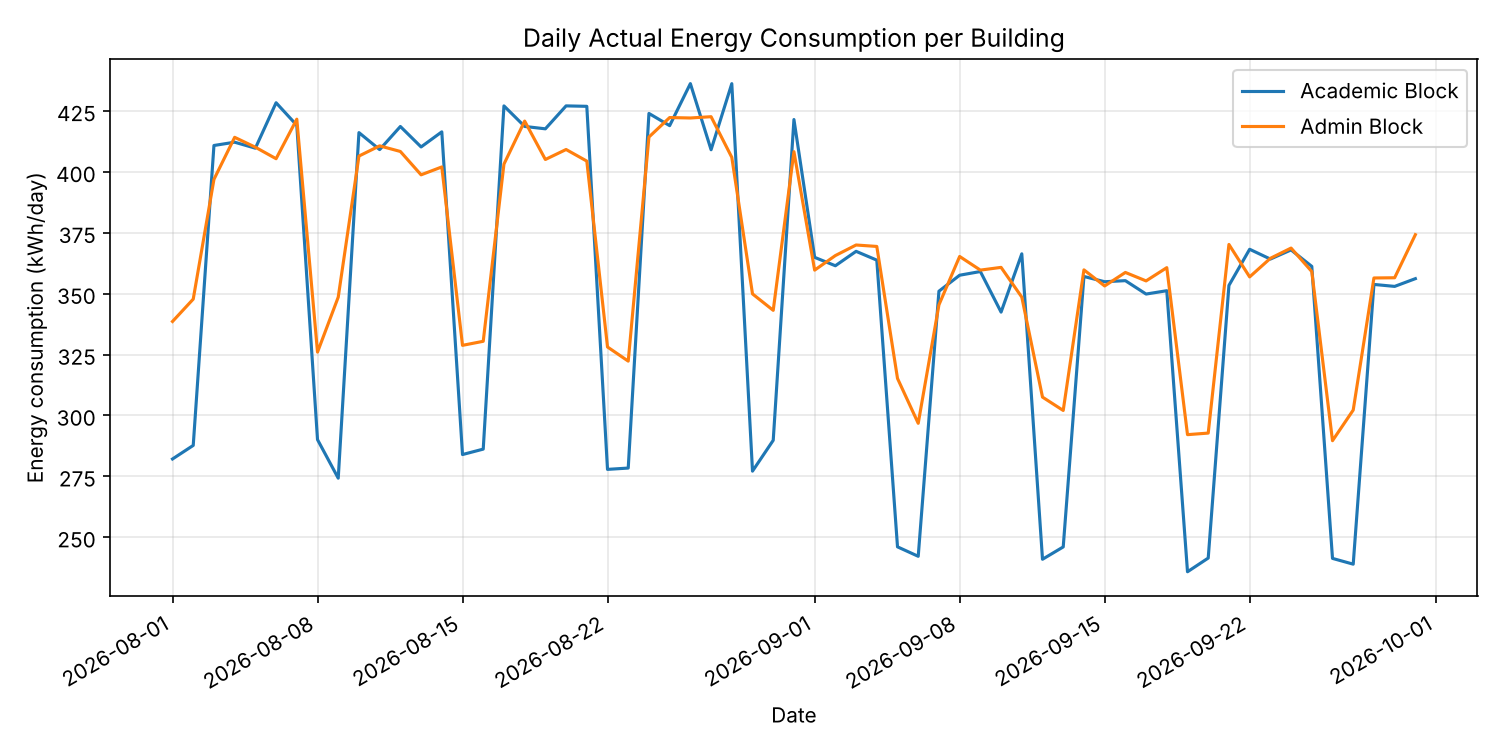

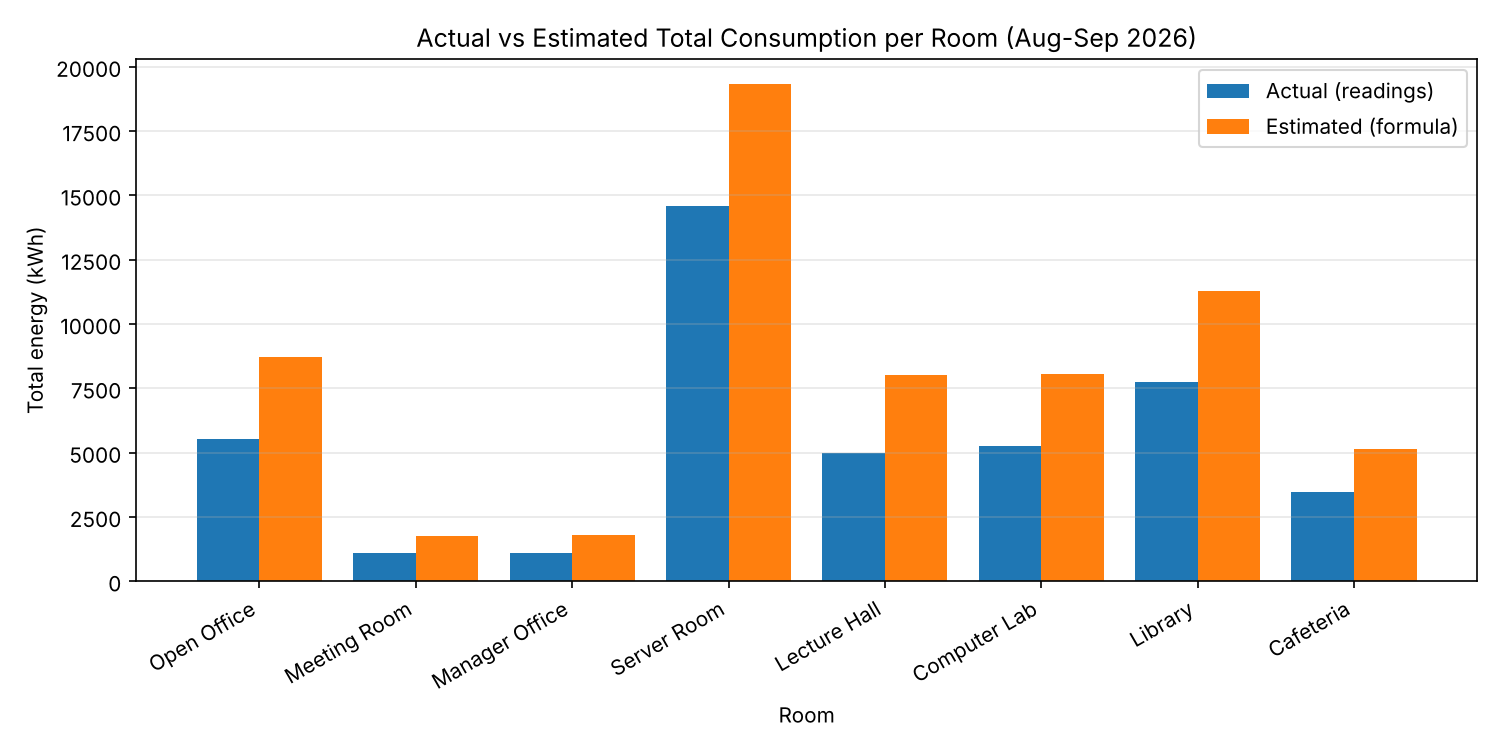

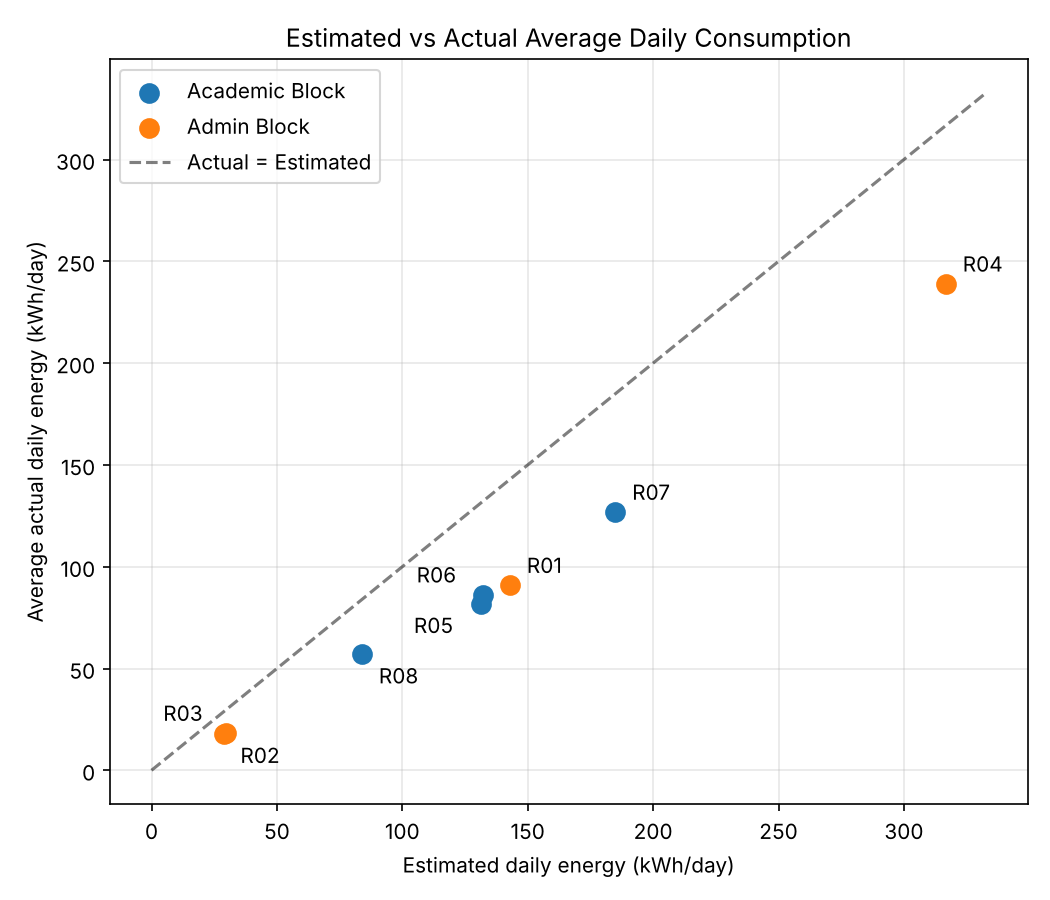

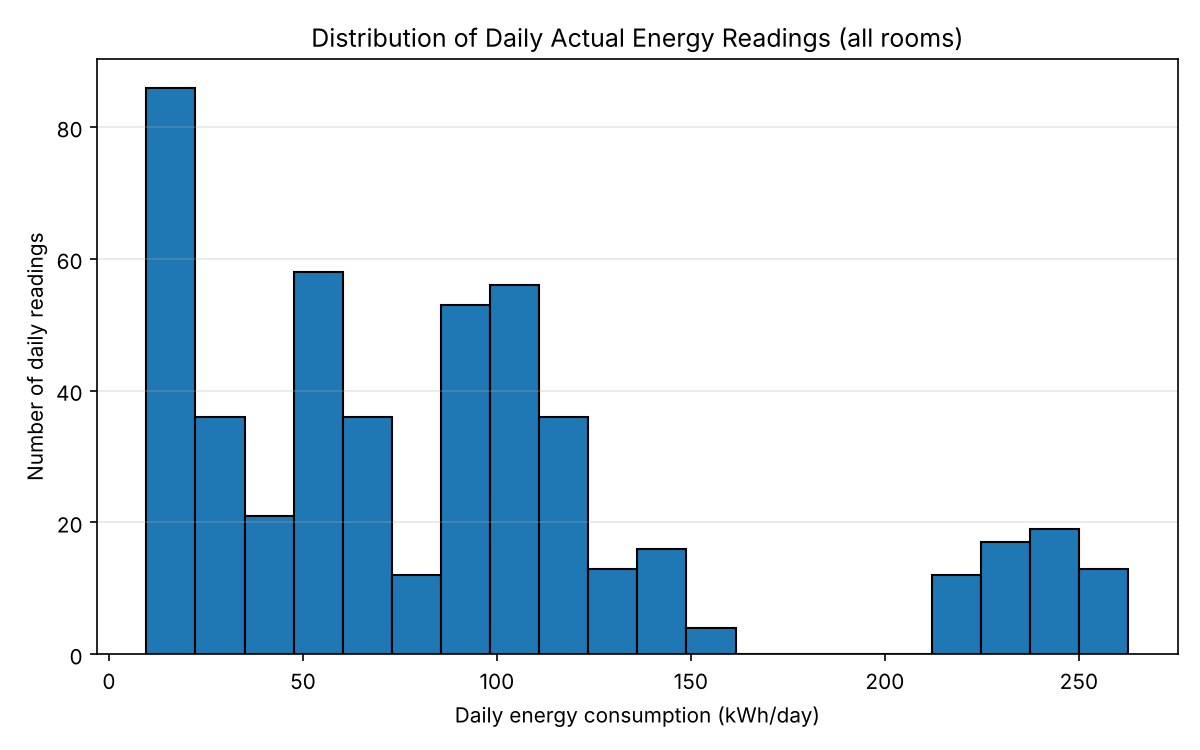

In [8]:
paths = analysis.make_all_charts(merged, comparison, "charts")
for path in paths:
    display(Image(path))

In [9]:
files = analysis.export_reports(merged, comparison, ac_result, "reports")
files

['reports/cleaned_merged_readings.csv', 'reports/report_by_room.csv', 'reports/report_by_building.csv', 'reports/report_by_month.csv', 'reports/report_by_building_month.csv', 'reports/report_ac_reduction.csv']

In [10]:
from tests.test_cases import run_tests

results = run_tests()
display(results)
print(f"{(results['result'] == 'PASS').sum()} of {len(results)} tests passed.")

6 of 6 tests passed.


,test,type,case,input,expected,actual,result
0,1,Valid,Daily energy of a normal room,"lighting 1, AC 5, equipment 2 kW, 8 h, 50 m2",64.0 kWh/day,64.0 kWh/day,PASS
1,2,Valid,"Boundary values (24 h, zero power / 0 h)",hours = 24 with 13.2 kW; all power = 0 with hours = 0,316.8 kWh/day and 0.0 kWh/day,316.8 kWh/day and 0.0 kWh/day,PASS
2,3,Valid,AC power reduced by 20 % (room R01),"R01 from rooms.csv, reduction = 20 %",143.0 -> 125.0 kWh/day,143.0 -> 125.0 kWh/day,PASS
3,4,Invalid,Area equal to zero,area_m2 = 0,ValueError (input rejected),"ValueError: area_m2 must be greater than 0, got 0.0",PASS
4,5,Invalid,Negative power,ac_kw = -3,ValueError (input rejected),"ValueError: ac_kw must be non-negative, got -3.0",PASS
5,6,Invalid,Operating hours above 24,hours_per_day = 25,ValueError (input rejected),"ValueError: hours_per_day must be between 0 and 24, got 25.0",PASS
